# Fine-tune Nori on your own table, from Python

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Synthefy/synthefy-nori/blob/main/examples/notebooks/nori-fine-tuning-sagemaker.ipynb)

Everything below runs in **your** AWS account: the training job, the model and the endpoint are yours. Synthefy ships
the Nori fine-tuning Algorithm through AWS Marketplace and the `synthefy` Python package; it never sees your data.

Before you start:

1. Subscribe to the Algorithm, create the execution role and check your instance quota, as described in the package
   README, section "Nori: Fine-tuning on Amazon SageMaker".
2. Run the notebook where boto3 finds AWS credentials for the identity that section's caller policy is attached to: a
   SageMaker notebook, an instance role, or a profile from `aws configure` or `aws sso login`. The client takes no
   access keys. A hosted runtime such as Colab has none until you put them in its environment.
3. Fill in the four account values in the second code cell. The first cell installs the package.

The notebook writes a small synthetic table, so it runs as it is. To fine-tune on your own data, put your own
`train.csv`, `validation.csv` and `new.csv` in the working directory first and set `TARGET` to your target column.

In [ ]:
# Installs the client with its AWS extra, or upgrades an older one; does nothing when it is already there.
%pip install -q "synthefy[aws]>=7.3.0" pandas matplotlib

In [2]:
import logging
import time
from pathlib import Path

import boto3
import numpy as np
import pandas as pd
from pydantic import ValidationError
from synthefy import FineTuneHyperparameters, FineTuneJobRequest, SynthefyNoriClient, SynthefyNoriFineTuner
from synthefy.errors import SageMakerInvocationError

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", datefmt="%H:%M:%S")
logging.getLogger("botocore").setLevel(logging.WARNING)

REGION = "us-east-1"  # the region of your subscription, bucket and role
ALGORITHM = "arn:aws:sagemaker:us-east-1:...:algorithm/..."  # the Algorithm ARN from your Marketplace subscription
ROLE_ARN = "arn:aws:iam::ACCOUNT_ID:role/nori-fine-tune-execution"  # your SageMaker execution role (README)
BUCKET = "YOUR-BUCKET"  # in REGION, name containing "sagemaker"; the job reads nori/data/, writes nori/output/
S3_PREFIX = f"s3://{BUCKET}/nori"
TARGET = "target"  # the column to predict

## 1. The table

A CSV with one header row, numeric columns and one target. The job trains on every other column. The notebook uses
three files with the same columns:

- `train.csv`: the table the job trains on.
- `validation.csv`: optional. Rows the job validates on instead of holding out its own; it never trains on them.
- `new.csv`: rows the job never sees, kept for section 8, where predictions are compared with their targets.

The next cell writes a synthetic example of each, unless one of the three is already in the working directory. The
cell after it uploads the first two to the bucket the execution role can read.

In [3]:
def example_table(rows: int, seed: int) -> pd.DataFrame:
    """A synthetic regression table: eight numeric features and a target no straight line fits."""
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(rows, 8))
    weights = np.random.default_rng(1234).normal(size=4)  # fixed, so every table samples the same function
    y = np.sin(1.5 * x[:, 0]) + 0.5 * x[:, 1] ** 2 + x[:, 2] * x[:, 3] + np.tanh(x[:, 4:] @ weights / 2)
    y = y + 0.1 * rng.normal(size=rows)
    return pd.DataFrame(x, columns=[f"f{i}" for i in range(1, 9)]).assign(**{TARGET: y})


if not any(Path(name).exists() for name in ("train.csv", "validation.csv", "new.csv")):
    held_out = example_table(500, seed=1)
    example_table(2000, seed=0).to_csv("train.csv", index=False)
    held_out.iloc[:400].to_csv("validation.csv", index=False)
    held_out.iloc[400:].to_csv("new.csv", index=False)

In [4]:
s3 = boto3.client("s3", region_name=REGION)
s3.upload_file("train.csv", BUCKET, "nori/data/train/train.csv")
s3.upload_file("validation.csv", BUCKET, "nori/data/validation/validation.csv")  # optional
table = pd.read_csv("train.csv")
assert TARGET in table.columns, f"TARGET {TARGET!r} is not a column of train.csv"
features = [c for c in table.columns if c != TARGET]
print(table.shape, "rows x columns;", "features:", features)
table.head()

(2000, 9) rows x columns; features: ['f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8']


,f1,f2,f3,f4,f5,f6,f7,f8,target
0,0.125730,-0.132105,0.640423,0.104900,-0.535669,0.361595,1.304000,0.947081,1.098097
1,-0.703735,-1.265421,-0.623274,0.041326,-2.325031,-0.218792,-1.245911,-0.732267,0.787174
2,-0.544259,-0.316300,0.411631,1.042513,-0.128535,1.366463,-0.665195,0.351510,-0.225481
3,0.903470,0.094012,-0.743499,-0.921725,-0.457726,0.220195,-1.009618,-0.209176,1.666178
4,-0.159225,0.540846,0.214659,0.355373,-0.653829,-0.129614,0.783975,1.493431,0.661371


## 2. Describe the job

The request is checked **before** any AWS call: S3 locations, the hyperparameters in the job's own schema, an instance
type the base model fits, and a runtime that covers the whole bag. Nothing bills yet.

In [5]:
tuner = SynthefyNoriFineTuner(region_name=REGION)

request = FineTuneJobRequest(
    algorithm=ALGORITHM,
    role_arn=ROLE_ARN,
    training_data=f"{S3_PREFIX}/data/train/",
    validation_data=f"{S3_PREFIX}/data/validation/",  # optional: rows the job validates on instead of holding out its own
    output_path=f"{S3_PREFIX}/output/",
    hyperparameters=FineTuneHyperparameters(
        target_column=TARGET,
        model_name="ft-acme-churn-v1",  # the name your fine-tuned model will answer to
        base_model="nori-6m",
        bag=2,  # the number of children the job trains, 1 to 8; the fine-tuned model is built from them
        steps=30,
    ),
)
print(
    "instance:", request.instance_type, "| max runtime:", request.max_runtime_s, "s | job name is picked at submit time"
)

instance: ml.g5.xlarge | max runtime: 4500 s | job name is picked at submit time


### What a refusal looks like

A typo in the data path, or a base too large for the instance, is caught here instead of ten minutes into a billed job.

In [6]:
try:
    FineTuneJobRequest(
        algorithm=ALGORITHM,
        role_arn=ROLE_ARN,
        training_data=f"{S3_PREFIX}/data/train",  # no trailing slash: S3 would also match train-old/
        output_path=f"{S3_PREFIX}/output/",
        hyperparameters=FineTuneHyperparameters(target_column=TARGET, model_name="ft-acme-churn-v1"),
    )
except ValidationError as exc:
    print(exc)

1 validation error for FineTuneJobRequest
training_data
  Value error, training_data must be an S3 folder ending in '/' or one .csv object; got 's3://YOUR-BUCKET/nori/data/train'. SageMaker reads every key that starts with the given text, so a folder without its '/' also reads look-alike siblings, and the job reads only .csv files [type=value_error, input_value='s3://YOUR-BUCKET/nori/data/train', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/value_error


## 3. Start it

One `CreateTrainingJob` in your account, network-isolated. The SDK returns right away with the job name; the console's
Training jobs page shows the same job.

In [7]:
job = tuner.fine_tune(request)
print(job.job_name, "->", job.status)

01:49:01 started training job nori-ft-acme-churn-v1-20261006-204859: nori-6m on ml.g5.xlarge


nori-ft-acme-churn-v1-20261006-204859 -> InProgress


## 4. Follow it

`wait()` logs every status change. `get_logs(follow=True)` streams the job's own log lines as they appear.

In [8]:
t0 = time.monotonic()
job = tuner.wait(job.job_name, poll_s=20)
print(job.status, "|", job.secondary_status, "|", job.status_message)
print(f"{time.monotonic() - t0:.0f} s wall, {job.billable_seconds} billable seconds on {request.instance_type}")

01:49:01 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Starting: Starting the training job


01:49:21 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Pending: Training job waiting for capacity


01:51:43 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Pending: Preparing the instances for training


01:52:03 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Downloading: Downloading input data


01:52:23 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Downloading: Downloading the training image


01:53:44 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Training: Training image download completed. Training in progress.


01:54:25 training job nori-ft-acme-churn-v1-20261006-204859: InProgress / Uploading: Uploading generated training model


01:54:45 training job nori-ft-acme-churn-v1-20261006-204859: Completed / Completed: Training job completed


Completed | Completed | Training job completed
344 s wall, 165 billable seconds on ml.g5.xlarge


In [9]:
for line in tuner.get_logs(job.job_name):
    if line.startswith("nori-train:"):
        print(line)

nori-train: job model-name ft-acme-churn-v1 base nori-6m instance ml.g5.xlarge rows 2000 rows-used 2000 training-rows 2000 features 8 validation channel report-rows 400 bag 2 max-steps 30
nori-train: device cuda:0 (NVIDIA A10G) vram-gib 22.1 max-val-cells 2000000
nori-train: featurized-width 46 loaded-in-seconds 11.1
nori-train: val-mse-before 0.0110212 n-val-rows 400 scored-in-seconds 0.4 peak-gpu-gib 0.28 peak-host-gib 1.28
nori-train: child-index 0 done: steps-run 30 best-step 28 val-mse-best 0.00772055 n-val-rows 400 n-finetune-rows 1000 featurized-width 46 interrupted no joins-average yes seconds 10.8 peak-gpu-gib 0.68 peak-host-gib 1.57
nori-train: child-index 1 done: steps-run 30 best-step 29 val-mse-best 0.00787553 n-val-rows 400 n-finetune-rows 1000 featurized-width 46 interrupted no joins-average yes seconds 10.4 peak-gpu-gib 0.68 peak-host-gib 1.60
nori-train: wrote ft-acme-churn-v1.pt, nori-model-registry.json and a provisional training_report.json
nori-train: wrote the fin

## 5. Training curves

One row per validated step and child, parsed from the job's log: plot it, or save it next to the model.

,child,step,train_loss,val_mse
56,1,27,0.022613,0.007992
57,1,28,0.025586,0.007920
58,1,29,0.029955,0.007876
59,1,30,0.026178,0.007883


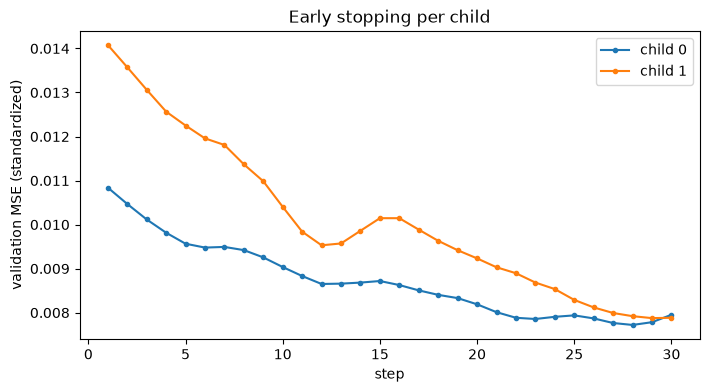

In [10]:
curves = pd.DataFrame(tuner.get_training_curves(job.job_name))
ax = None
for child, rows in curves.groupby("child"):
    ax = rows.plot(x="step", y="val_mse", ax=ax, label=f"child {child}", marker=".", figsize=(8, 4))
ax.set_ylabel("validation MSE (standardized)")
ax.set_title("Early stopping per child")
curves.tail(4)

## 6. The report

`training_report.json` is read straight out of the artifact: the base model's score and the **fine-tuned** model's, on
the same rows the job never trained on, and `model_version`, the digest the endpoint will later report back.

In [11]:
report = tuner.get_training_report(job.job_name)
print(f"val_mse_before = {report.val_mse_before:.5f}   val_mse_after = {report.val_mse_after:.5f}")
print(
    "children:",
    report.children,
    "| rows used:",
    report.n_rows_used,
    "| validation:",
    report.validation_source,
    report.n_val_rows,
    "rows | cut short:",
    report.cut_short,
)
print("model_version:", report.model_version)

val_mse_before = 0.01102   val_mse_after = 0.00670
children: 2 | rows used: 2000 | validation: channel 400 rows | cut short: False
model_version: sha256:10f32422f3c04b03ac5ecf3d4d143c3d5f1b7530487a4589d9227ac436559b6f


## 7. Deploy it

Four SageMaker resources, made in order and waited on: a model package over the artifact, a model, an endpoint config,
an asynchronous endpoint. The returned `FineTunedEndpoint` remembers them all.

The endpoint bills by the hour from here until section 10 deletes it, whether or not it serves a request: about $1.41
an hour on `ml.g5.xlarge` in us-east-1. If a cell in between fails, run the last cell anyway.

In [12]:
t0 = time.monotonic()
endpoint = tuner.deploy(job, endpoint_name="ft-acme-churn-v1", instance_type="ml.g5.xlarge")
print(endpoint.status, f"after {time.monotonic() - t0:.0f} s on", endpoint.instance_type)
print(
    "package:",
    endpoint.model_package_arn.rsplit("/", 1)[-1],
    "| model:",
    endpoint.sagemaker_model_name,
    "| config:",
    endpoint.endpoint_config_name,
)

01:54:52 created model package arn:aws:sagemaker:us-east-1:123456789012:model-package/nori-ft-acme-churn-v1-20261006-204859


01:55:40 created SageMaker model ft-acme-churn-v1


01:55:41 creating endpoint ft-acme-churn-v1 on ml.g5.xlarge for model ft-acme-churn-v1


01:55:41 endpoint ft-acme-churn-v1: Creating


02:00:15 endpoint ft-acme-churn-v1: InService


InService after 326 s on ml.g5.xlarge
package: nori-ft-acme-churn-v1-20261006-204859 | model: ft-acme-churn-v1 | config: ft-acme-churn-v1-20261006-205450


## 8. Predict with it

`tuner.create_client(endpoint, ...)` builds the same `SynthefyNoriClient` every Nori user has, in SageMaker mode,
bound to this endpoint and the fine-tuned model's name. Context rows go with each request; the endpoint keeps nothing of
your table. `new.csv` holds rows the job never saw, so the comparison below is an honest one; the validation file would
flatter it, since those rows also steered the training.

In [13]:
new_rows = pd.read_csv("new.csv")  # rows the job never saw: same columns, same order
X_test, truth = new_rows[features].head(20), new_rows[TARGET].head(20)
context = table.sample(n=500, random_state=0)

with tuner.create_client(endpoint, s3_staging_uri=f"{S3_PREFIX}/invocations/") as client:
    t0 = time.monotonic()
    prediction = client.predict(
        X_train=context[features], y_train=context[TARGET], X_test=X_test, categorical_columns=None, as_pandas=True
    )
    print(f"{len(prediction)} predictions in {time.monotonic() - t0:.1f} s")
    print("answered by model_version", client.last_model_version)
    print("same model the report describes:", client.last_model_version == report.model_version)

pd.DataFrame({"prediction": prediction.values, "truth": truth.values}).round(3).head(8)

20 predictions in 4.9 s
answered by model_version sha256:10f32422f3c04b03ac5ecf3d4d143c3d5f1b7530487a4589d9227ac436559b6f
same model the report describes: True


,prediction,truth
0,1.377,1.536
1,2.546,2.408
2,-2.032,-2.101
3,-0.909,-1.039
4,-0.321,-0.224
5,1.971,1.973
6,0.250,0.342
7,3.498,3.603


## 9. A wrong model name is refused

The endpoint serves one model. A request for any other name, even a valid `ft-` one, comes back as an error instead
of an answer from a different model.

In [14]:
try:
    with SynthefyNoriClient(
        mode="sagemaker",
        model="ft-acme-churn-v2",
        endpoint_name=endpoint.endpoint_name,
        region_name=REGION,
        s3_staging_uri=f"{S3_PREFIX}/invocations/",
    ) as wrong:
        wrong.predict(
            X_train=context[features], y_train=context[TARGET], X_test=X_test.head(2), categorical_columns=None
        )
except SageMakerInvocationError as exc:
    print(type(exc).__name__ + ":", str(exc)[:160])

SageMakerInvocationError: SageMaker invocation b330b6ae88f04e71bb5e5c63731e37ba failed: {"detail":"Requested model 'ft-acme-churn-v2' is not available on this endpoint. Choose one of ['f


## 10. Switch it off

`undeploy()` deletes the endpoint, waits, then the config and the model. The package and the artifact stay: a second
`deploy()` reuses them.

In [15]:
tuner.undeploy(endpoint)
tuner.close()
print("endpoint, config and model deleted; package", endpoint.model_package_arn.rsplit("/", 1)[-1], "kept")

02:00:24 deleting endpoint ft-acme-churn-v1


02:00:35 deleted endpoint config ft-acme-churn-v1-20261006-205450


02:00:36 deleted SageMaker model ft-acme-churn-v1


endpoint, config and model deleted; package nori-ft-acme-churn-v1-20261006-204859 kept
